In [1]:
import os

import pandas as pd 
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler


In [4]:
data = pd.read_csv("data/data.csv")
data.head(-5)

,id,Rank,Title,Primary Artists,Featuring Artists,Date,Danceability,Energy,Speechiness,Acousticness,...,detected_languages,num_languages,language_confidences,artist_id,explicit,track_popularity,artist_followers,artist_genres,artist_popularity,Loudness
0,47EiUVwUp4C9fGccaPuUCS,1,dákiti,"bad bunny, jhayco",NaN,26/11/2020,0.731,0.573,0.054,0.401,...,SPANISH,1,SPANISH: 1.0,4q3ewBCX7sLwd24euuV69X,True,78,102185553.0,"reggaeton, trap latino, urbano latino, latin",95.0,-10.059
1,7igeByaBM0MgGsgXtNxDJ7,1,positions,ariana grande,NaN,29/10/2020,0.736,0.802,0.086,0.468,...,ENGLISH,1,ENGLISH: 1.0,66CXWjxzNUsdJxJ2JdwvnR,True,0,107261237.0,pop,90.0,-4.759
2,3qQbCzHBycnDpGskqOWY0E,1,ella baila sola,"eslabon armado, peso pluma",NaN,29/05/2023,0.668,0.758,0.033,0.483,...,SPANISH,1,SPANISH: 1.0,0XeEobZplHxzM9QzFQWLiR,False,73,6434994.0,"corridos tumbados, sad sierreño, corrido, sier...",75.0,-5.176
3,0Yde1VrWbGF2Tus2AQhMuT,1,circles,post malone,NaN,06/09/2019,0.703,0.756,0.038,0.222,...,ENGLISH,1,ENGLISH: 1.0,246dkjvS1zLTtiykXe5h60,False,0,47686394.0,NaN,85.0,-3.407
4,0TK2YIli7K1leLovkQiNik,1,señorita,"camila cabello, shawn mendes",NaN,25/07/2019,0.759,0.540,0.029,0.037,...,ENGLISH,1,ENGLISH: 1.0,7n2wHs1TKAczGzO7Dd2rGr,False,79,45665812.0,NaN,81.0,-6.039
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9151,2dl5K2ScW7jYhAhuem06cm,200,problema,daddy yankee,NaN,20/05/2021,0.773,0.800,0.099,0.061,...,SPANISH,1,SPANISH: 1.0,4VMYDCV2IEDYJArk749S6m,True,57,37766169.0,"reggaeton, latin",85.0,-3.170
9152,1FUViuNSldssMIawrOXF2i,200,i got you,bebe rexha,NaN,08/06/2017,0.609,0.887,0.051,0.050,...,ENGLISH,1,ENGLISH: 1.0,64M6ah0SkkRsnPGtGiRAbb,False,47,9827091.0,NaN,75.0,-4.749
9153,7z84Fwf1R3Z2BwHCP620CI,200,this is why,paramore,NaN,01/10/2022,0.723,0.737,0.039,0.004,...,ENGLISH,1,ENGLISH: 1.0,74XFHRwlV6OrjEM0A2NCMF,False,0,9771643.0,"pop punk, emo",78.0,-7.566
9154,7wBJfHzpfI3032CSD7CE2m,200,stargazing,travis scott,NaN,14/05/2020,0.487,0.789,0.044,0.009,...,ENGLISH,1,ENGLISH: 1.0,0Y5tJX1MQlPlqiwlOH1tJY,True,73,41006554.0,rap,89.0,-3.690


In [6]:
data = pd.read_csv("data/data.csv")
data.head()

# thinking of one hot encoding the nationaility and continent columns and the detected_languages column
# and then applying pca to reduce the dimensionality of the data before fitting gaussians to the artists
explicit_dummies = pd.get_dummies(data['explicit'], prefix='explicit')
data = pd.concat([data, explicit_dummies], axis=1)
data.drop(columns=['explicit'], inplace=True) # drop original column
nationality_dummies = pd.get_dummies(data['Nationality'], prefix='Nationality')
continent_dummies = pd.get_dummies(data['Continent'], prefix='Continent')
detected_languages_dummies = pd.get_dummies(data['detected_languages'], prefix='detected_languages')
data = pd.concat([data, nationality_dummies, continent_dummies, detected_languages_dummies], axis=1)
data.drop(columns=['Nationality', 'Continent', 'detected_languages'], inplace=True) # drop original columns
#data.head()
# write the modified data to a new csv file
#data.to_csv("data/features-annotated-artistless-with-lyrics-and-languages-onehot.csv", index=False)

#extract the new song features list after one hot encoding
data_cols = data.columns.tolist()
print(data_cols)
data.iloc[0]["num_languages"]

['id', 'Rank', 'Title', 'Primary Artists', 'Featuring Artists', 'Date', 'Danceability', 'Energy', 'Speechiness', 'Acousticness', 'Instrumentalness', 'Valence', 'Points (Total)', 'lyrics', 'num_languages', 'language_confidences', 'artist_id', 'track_popularity', 'artist_followers', 'artist_genres', 'artist_popularity', 'Loudness', 'explicit_False', 'explicit_True', 'Nationality_albania', 'Nationality_algeria', 'Nationality_argentina', 'Nationality_australia', 'Nationality_austria', 'Nationality_azerbaijan', 'Nationality_barbados', 'Nationality_belgium', 'Nationality_bonaire', 'Nationality_brazil', 'Nationality_canada', 'Nationality_chili', 'Nationality_colombia', 'Nationality_costa rica', 'Nationality_cuba', 'Nationality_czech republic', 'Nationality_denmark', 'Nationality_dominican republic', 'Nationality_ecuador', 'Nationality_finland', 'Nationality_france', 'Nationality_germany', 'Nationality_ghana', 'Nationality_greece', 'Nationality_iceland', 'Nationality_india', 'Nationality_indon

np.int64(1)

In [11]:
# Split the comma-separated artists and create a row for each artist-song pair
data_exploded = data.assign(Primary_Artists_List=data['Primary Artists'].str.split(', ')).explode('Primary_Artists_List')

# Now group by individual artist
songs_by_artist = data_exploded.groupby('Primary_Artists_List')

# Example: Get all songs by a specific artist
drake_songs = songs_by_artist.get_group('drake')
print(drake_songs[['Title', 'Primary Artists']])

                       Title         Primary Artists
15            in my feelings                   drake
38              toosie slide                   drake
103       don't matter to me  drake, michael jackson
159                  nonstop                   drake
178               god's plan                   drake
...                      ...                     ...
8894  ratchet happy birthday                   drake
8914     behind barz - bonus                   drake
8937         walk it talk it            drake, migos
9076              free smoke                   drake
9083            falling back                   drake

[177 rows x 2 columns]


In [12]:

artists = os.path.join(os.getcwd(), 'data', 'artists.csv')
artists_df = pd.read_csv(artists)
artists_df.head()


,Artist,Mean Danceability,Std Danceability,Mean Energy,Std Energy,Mean Loudness,Std Loudness,Mean Speechiness,Std Speechiness,Mean Acousticness,Std Acousticness,Mean Instrumentalness,Std Instrumentalness,Mean Valence,Std Valence,Count
0,drake,0.711716,0.151289,0.549638,0.153531,-6402.349258,3444.709399,0.202100,0.140503,0.200074,0.232417,0.010201,0.065975,0.373162,0.208277,229
1,taylor swift,0.592329,0.113179,0.554347,0.175523,-7408.700833,3317.588195,0.064769,0.058960,0.337579,0.326075,0.004301,0.037129,0.392620,0.189788,216
2,future,0.760352,0.123411,0.582162,0.108463,-5987.031508,2562.616316,0.220631,0.119358,0.104190,0.134780,0.004581,0.030612,0.396207,0.210416,179
3,juice wrld,0.667318,0.108455,0.606345,0.123862,-5771.773986,3311.928867,0.155899,0.138577,0.193385,0.223225,0.002926,0.024425,0.416068,0.191834,148
4,bts,0.639693,0.109827,0.725536,0.144852,-4873.853071,2283.009199,0.108071,0.113135,0.117629,0.162112,0.026800,0.142707,0.513664,0.188043,140


[[0.731 0.573 0.054 ... False False False]
 [0.736 0.802 0.086 ... False False False]
 [0.668 0.758 0.033 ... False False False]
 ...
 [0.437 0.716 0.05 ... False False False]
 [0.734 0.607 0.081 ... False False False]
 [0.563 0.703 0.07 ... False False False]]


/var/folders/0s/_tltrxz97fb0_px4cdx14ys40000gn/T/ipykernel_11328/814834463.py:47: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


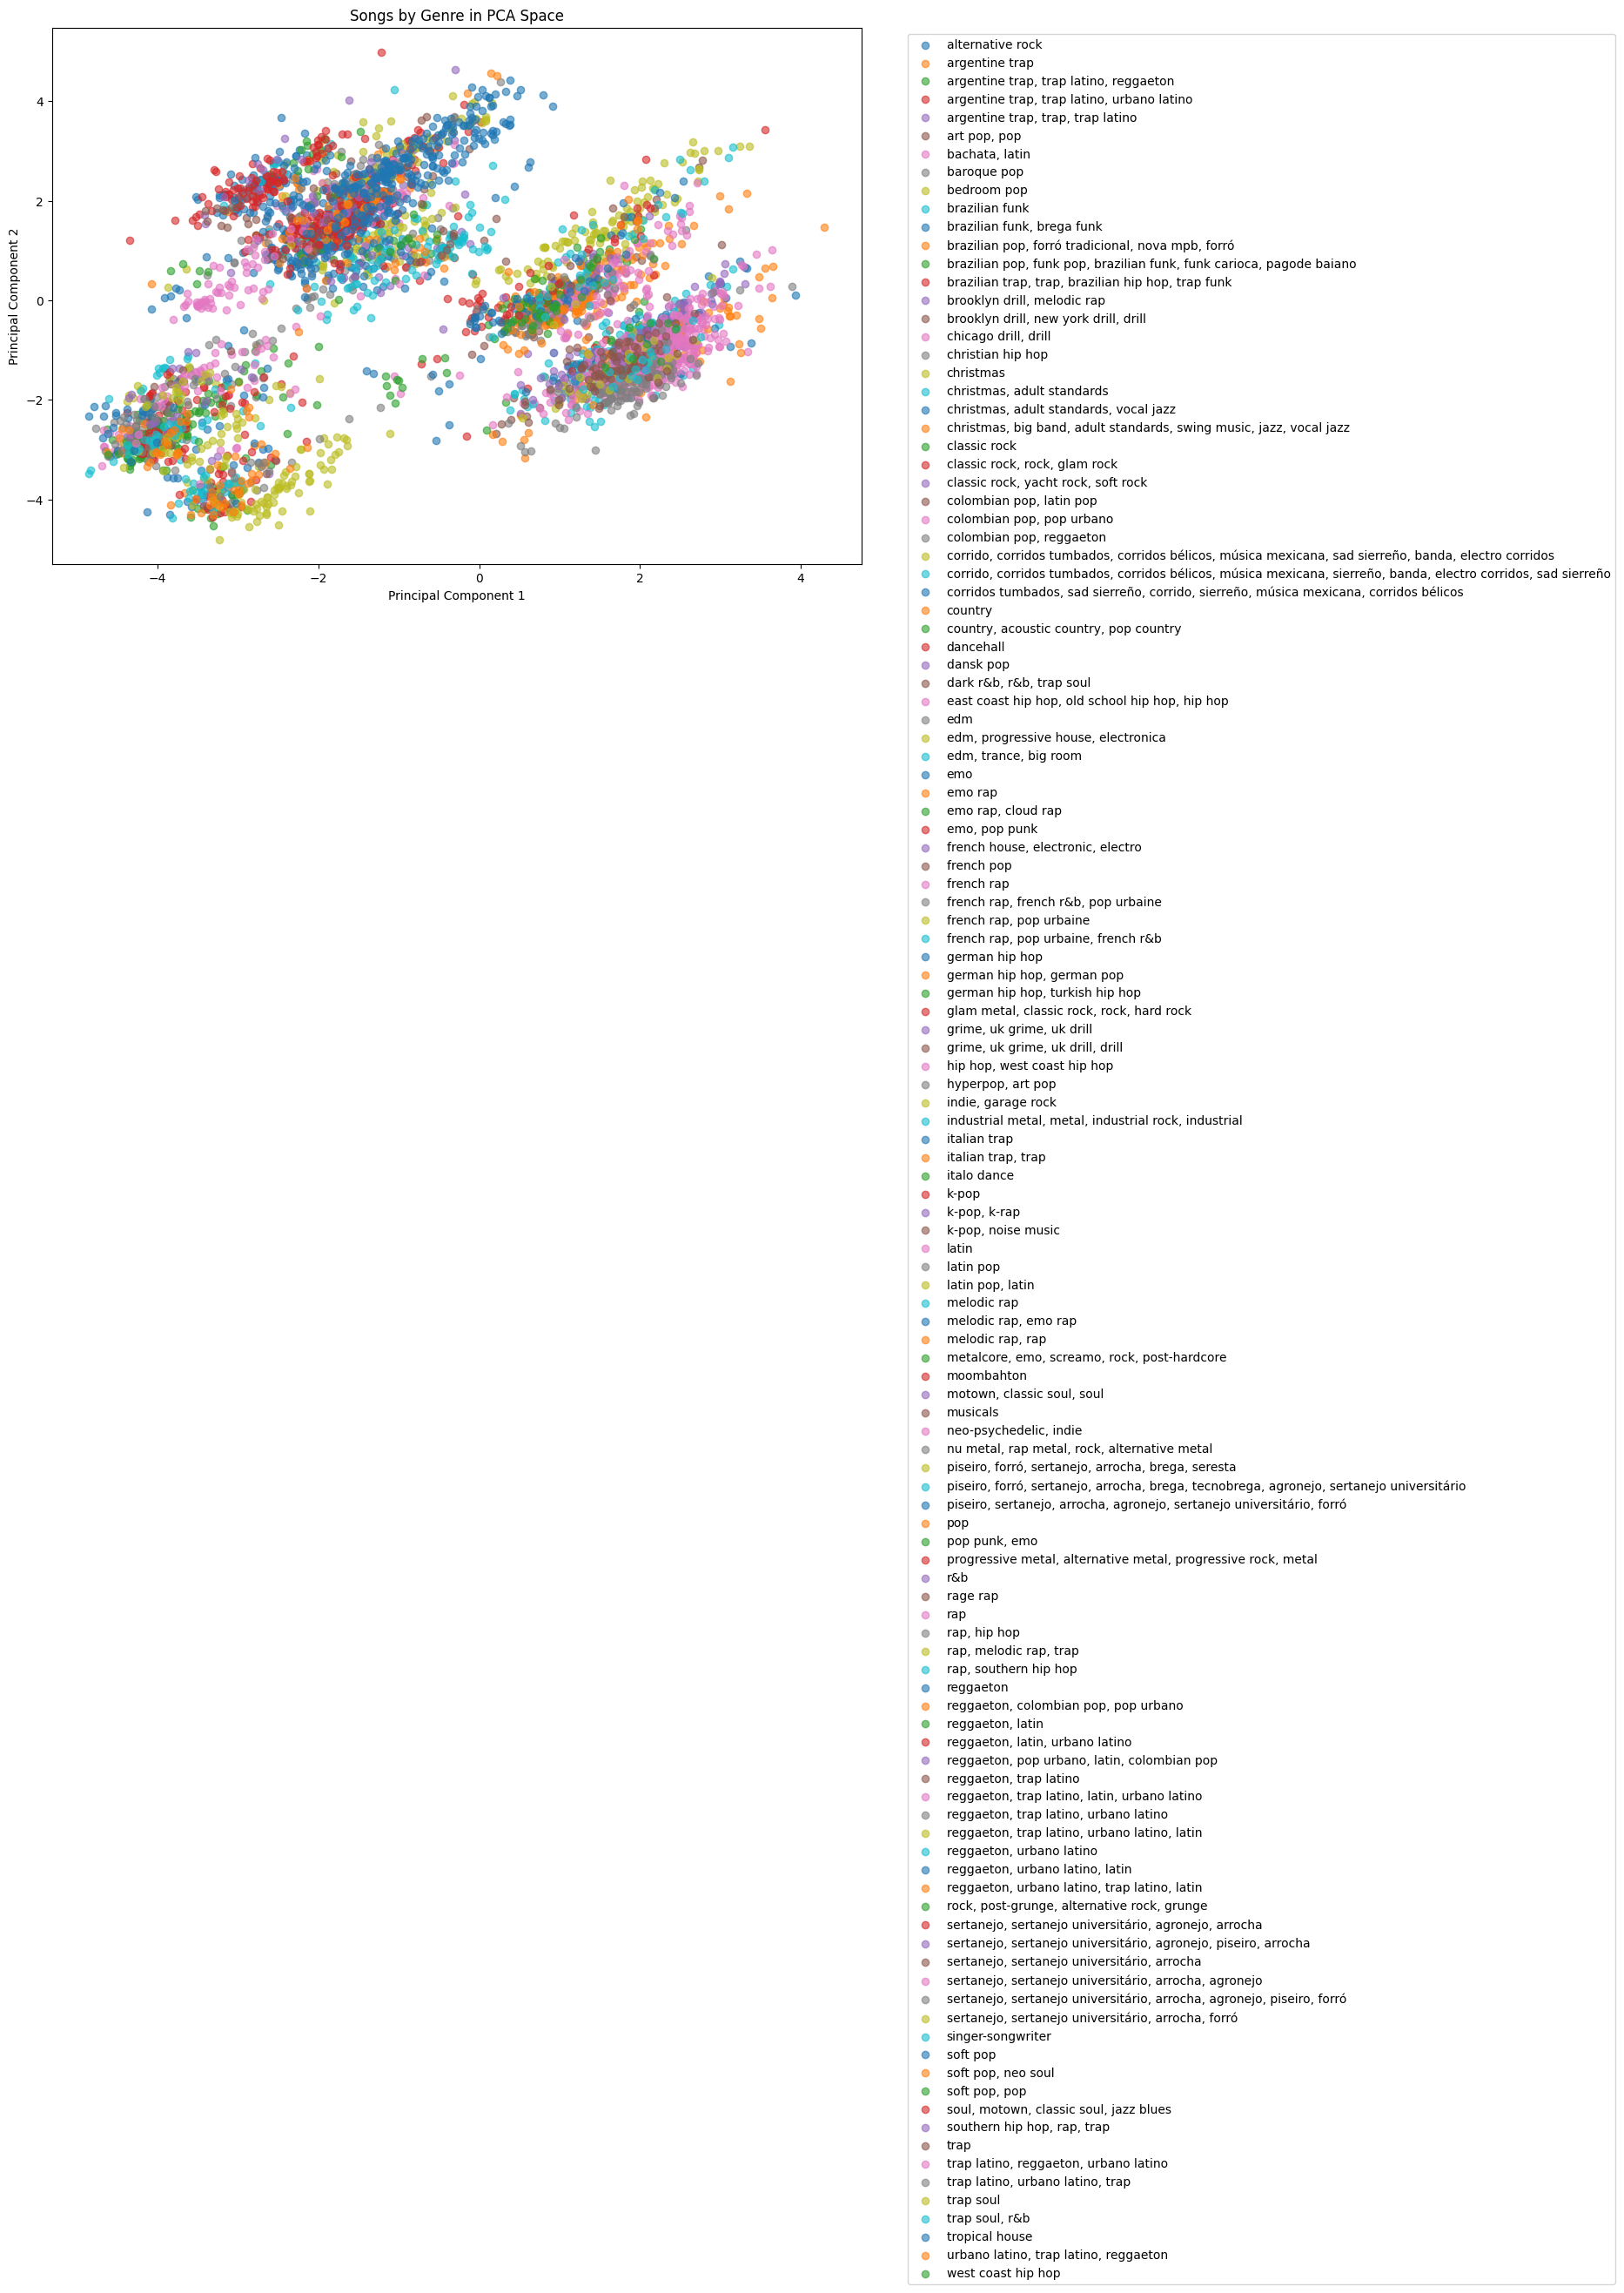

In [7]:
song_features = ['Danceability', 'Energy', 'Speechiness', 'Acousticness', 'Instrumentalness', 'Valence', 'Points (Total)', 'track_popularity', 'artist_followers', 'artist_popularity', 'Loudness', 'explicit_False', 'explicit_True', 'Nationality_albania', 'Nationality_algeria', 'Nationality_argentina', 'Nationality_australia', 'Nationality_austria', 'Nationality_azerbaijan', 'Nationality_barbados', 'Nationality_belgium', 'Nationality_bonaire', 'Nationality_brazil', 'Nationality_canada', 'Nationality_chili', 'Nationality_colombia', 'Nationality_costa rica', 'Nationality_cuba', 'Nationality_czech republic', 'Nationality_denmark', 'Nationality_dominican republic', 'Nationality_ecuador', 'Nationality_finland', 'Nationality_france', 'Nationality_germany', 'Nationality_ghana', 'Nationality_greece', 'Nationality_iceland', 'Nationality_india', 'Nationality_indonesia', 'Nationality_ireland', 'Nationality_israel', 'Nationality_italy', 'Nationality_jamaica', 'Nationality_japan', 'Nationality_kazakhstan', 'Nationality_kosovo', 'Nationality_lithuania', 'Nationality_malta', 'Nationality_mexico', 'Nationality_moldavia', 'Nationality_morocco', 'Nationality_netherlands', 'Nationality_new zealand', 'Nationality_nigeria', 'Nationality_norway', 'Nationality_pakistan', 'Nationality_panama', 'Nationality_philippines', 'Nationality_poland', 'Nationality_portugal', 'Nationality_puerto rico', 'Nationality_romania', 'Nationality_russia', 'Nationality_scotland', 'Nationality_south africa', 'Nationality_south korea', 'Nationality_spain', 'Nationality_sri lanka', 'Nationality_suecia', 'Nationality_sweden', 'Nationality_swiss', 'Nationality_thailand', 'Nationality_turkey', 'Nationality_ukraine', 'Nationality_united kingdom', 'Nationality_united states', 'Nationality_unknown', 'Nationality_venezuela', 'Continent_africa', 'Continent_anglo-america', 'Continent_asia', 'Continent_europe', 'Continent_latin-america', 'Continent_oceania', 'Continent_unknown', 'detected_languages_ARABIC', 'detected_languages_AZERBAIJANI', 'detected_languages_BENGALI', 'detected_languages_BOSNIAN', 'detected_languages_CATALAN', 'detected_languages_CHINESE', 'detected_languages_DANISH', 'detected_languages_DUTCH', 'detected_languages_ENGLISH', 'detected_languages_ENGLISH, TAGALOG', 'detected_languages_FINNISH', 'detected_languages_FRENCH', 'detected_languages_GERMAN', 'detected_languages_GREEK', 'detected_languages_HEBREW', 'detected_languages_HINDI', 'detected_languages_HUNGARIAN', 'detected_languages_INDONESIAN', 'detected_languages_ITALIAN', 'detected_languages_JAPANESE', 'detected_languages_KOREAN', 'detected_languages_LATVIAN', 'detected_languages_MALAY', 'detected_languages_PERSIAN', 'detected_languages_POLISH', 'detected_languages_PORTUGUESE', 'detected_languages_PUNJABI', 'detected_languages_RUSSIAN', 'detected_languages_SLOVENE', 'detected_languages_SPANISH', 'detected_languages_SWEDISH', 'detected_languages_TAGALOG', 'detected_languages_TSWANA', 'detected_languages_TURKISH', 'detected_languages_UKRAINIAN', 'detected_languages_URDU', 'detected_languages_VIETNAMESE', 'detected_languages_WELSH']

X= data[song_features].values
print(X)

# normalise the data
scaler = StandardScaler()
X = scaler.fit_transform(X)
# Apply PCA

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

# Add PCA components to dataframe
data['PCA1'] = X_pca[:, 0]
data['PCA2'] = X_pca[:, 1]

# Explode artists and group
# data_exploded = data.assign(
#     Primary_Artists_List=data['Primary Artists'].str.split(', ')
# ).explode('Primary_Artists_List')

# songs_by_artist = data_exploded.groupby('Primary_Artists_List')

# pca with the y values being the genres
y = data['artist_genres']


# #plot the pca analysis as a scatter plot with artists being different colors
# plt.figure(figsize=(10,7))
# scatter = plt.scatter(X_pca[:,0], X_pca[:,1], c='blue', alpha=0.5)
# plt.title("PCA of Song Features")
# plt.xlabel("Principal Component 1")
# plt.ylabel("Principal Component 2")
# plt.grid()
# plt.show()

# Plot each genre with different color
plt.figure(figsize=(12, 8))
for genre, group in data.groupby('artist_genres'):
    if len(group) > 5:  # Only plot genres with more than 5 songs
        plt.scatter(group['PCA1'], group['PCA2'], label=genre, alpha=0.6)
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('Songs by Genre in PCA Space')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()
# then fit gaussians to the genres

# or fit gaussians to the genre of songs


In [21]:
%pip install -q sentence-transformers

Note: you may need to restart the kernel to use updated packages.


In [ ]:
# what genres have the same semantic meanings
# getting the word embeddings for each genre and then calculating the cosine similarity between them

from pathlib import Path
from sentence_transformers import SentenceTransformer, util



/Users/victoria/Documents/University/AML/AML_Spotify/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
